In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.datasets import make_circles
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.plotting import plot_decision_regions

#                                                       Theory
```js
        The theory of AdaBoost, how it works and the math behind it described in "Adaboost.pdf" which is in the Theory folder. MUST READ "Adaboost.pdf" WHERE I ALSO EXPLAINED WHAT ALPHA VALUE MEANS IN PAGE 5 AND IN THE LAST PAGE THE DIFFERENCE BETWEEN BAGGING AND BOOSTING.
        
        learning_rate hyperparameter in AdaBoost :
        ------------------------------------------
                The learning rate determines the rate at which the boosting algorithm learns from each iteration. A lower value of eta means slower learning, as it scales down the contribution of each tree in the ensemble, thus helping to prevent overfitting. Either way by hyperparameter tuning we’ll find out which learning_rate is best for.

        Don’t worry on Adaboost since we’ll be working with XGBoost mainly but for boosting Adaboost is the easiest intro.
```

#                                                       Implementation

[[-0.12619025  0.30737706]
 [ 0.31067317  0.30176983]
 [-0.36684693  0.91305711]
 [-0.69756791 -0.29159005]
 [ 0.4999156  -0.8663295 ]] 

[1 1 1 1 0]


<Axes: >

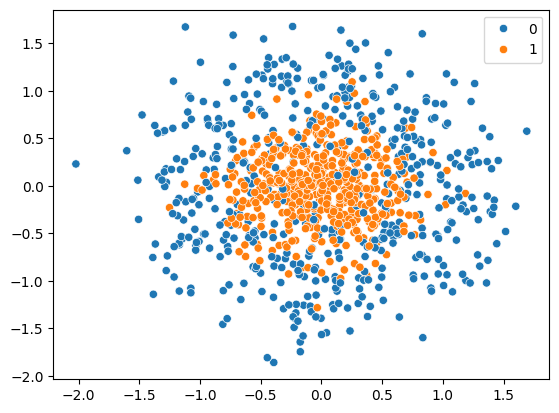

In [20]:
#                                              Dataset creation and visualization

X, y = make_circles(n_samples = 1000, noise = 0.37, factor = 0.1, random_state = 42) # (500, 2), (500).
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

print(X[:5], '\n')
print(y[:5])

sns.scatterplot(x = X[:, 0], y = X[:, 1], hue = y) # The scatterplot of X, y.

In [ ]:
#                               Finding the best values of hyperparameters for AdaBoostClassifier.

parameters = {'n_estimators'  : [20, 50, 100, 150, 200],
              'learning_rate' : [0.1, 0.01, 0.001, 0.0001],
              'random_state'  : [42, 50, 60]
}

search = GridSearchCV(estimator = AdaBoostClassifier(), # By default estimator = DecisionTreeClassifier(max_depth = 1) in
                      param_grid = parameters,          # AdaBoostClassifier().
                      n_jobs = -1,
                      cv = 5,
                      scoring = 'accuracy')

search.fit(X = x_train, y = y_train)

print(f"Best accuracy obtained after hyperparmater tuning = {search.best_score_}.\n")
print(f"Best hyperparameter values = :\n{search.best_params_}.")

note = """
    search.best_score_ is that average cross-validation accuracy on the training data. So
"""

Best accuracy obtained after hyperparmater tuning = 0.8262499999999999.

Best hyperparameter values = :
{'learning_rate': 0.1, 'n_estimators': 150, 'random_state': 42}.


Accuracy on testing  = 0.725.


<Axes: >

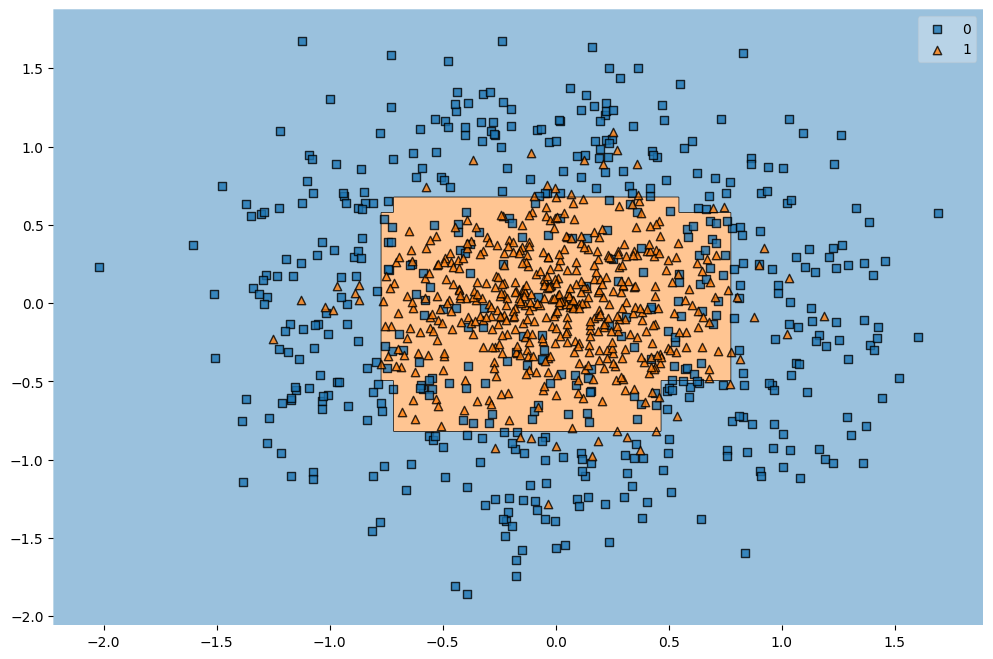

In [ ]:
#                        Setting those above best hyperparameters in Adaboost and visualising how it classified.

adaboost = AdaBoostClassifier(n_estimators = 150,
                              learning_rate = 0.1,
                              random_state = 42
)

adaboost.fit(X = x_train, y = y_train)

print(f"Accuracy on testing  = {accuracy_score(y_true = y_test, y_pred = adaboost.predict(x_test))}.")

plt.figure(figsize = (12, 8))
plot_decision_regions(X = X, y = y, clf = adaboost, n_jobs = -1, zoom_factor = 5)

# Adaboost can be used for regression too but mostly used for classification. Also mainly we'll use XGBoost, not this.